<a href="https://colab.research.google.com/github/Kritika-rk2023/Major-project/blob/main/FEMTO_Dataset_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import kurtosis, skew
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

def generate_femto_bearing_stream(num_samples=2500):
    t = np.linspace(0, 100, num_samples)

    wear_profile = np.exp(t / 25.0) / np.exp(4.0)
    vib_horiz = np.random.normal(0, 0.2 + 1.2 * wear_profile, num_samples)
    vib_vert  = np.random.normal(0, 0.15 + 0.9 * wear_profile, num_samples)

    window = 20
    df = pd.DataFrame({
        'Horiz_Raw': vib_horiz,
        'Vert_Raw': vib_vert
    })

    features = pd.DataFrame()
    features['Horiz_RMS'] = df['Horiz_Raw'].rolling(window, min_periods=1).apply(lambda x: np.sqrt(np.mean(x**2)))
    features['Vert_RMS'] = df['Vert_Raw'].rolling(window, min_periods=1).apply(lambda x: np.sqrt(np.mean(x**2)))
    features['Horiz_Kurtosis'] = df['Horiz_Raw'].rolling(window, min_periods=1).apply(lambda x: kurtosis(x))
    features['Vert_Kurtosis'] = df['Vert_Raw'].rolling(window, min_periods=1).apply(lambda x: kurtosis(x))
    features['Horiz_PeakToPeak'] = df['Horiz_Raw'].rolling(window, min_periods=1).apply(lambda x: np.ptp(x))
    features['Vert_PeakToPeak'] = df['Vert_Raw'].rolling(window, min_periods=1).apply(lambda x: np.ptp(x))
    features['Horiz_Skewness'] = df['Horiz_Raw'].rolling(window, min_periods=1).apply(lambda x: skew(x))
    features['Horiz_Variance'] = df['Horiz_Raw'].rolling(window, min_periods=1).var().fillna(0)

    features['Crest_Factor'] = (features['Horiz_PeakToPeak'] / 2.0) / (features['Horiz_RMS'] + 1e-6)
    features['RUL'] = np.linspace(num_samples, 0, num_samples)

    return features.dropna()

print("Extracting statistical vibration features for FEMTO Bearing (Dataset 3)...")
femto_df = generate_femto_bearing_stream(num_samples=2500)

print(f"FEMTO Feature Matrix Shape: {femto_df.shape}")
print(femto_df.head())

Extracting statistical vibration features for FEMTO Bearing (Dataset 3)...
FEMTO Feature Matrix Shape: (2499, 10)
   Horiz_RMS  Vert_RMS  Horiz_Kurtosis  Vert_Kurtosis  Horiz_PeakToPeak  \
1   0.080931  0.132314       -2.000000      -2.000000          0.140957   
2   0.106118  0.112633       -1.500000      -1.500000          0.174515   
3   0.192478  0.110065       -1.011591      -1.734025          0.368938   
4   0.173721  0.127387       -0.961231      -1.481020          0.390252   
5   0.160001  0.129132       -0.698463      -1.311527          0.390256   

   Vert_PeakToPeak  Horiz_Skewness  Horiz_Variance  Crest_Factor          RUL  
1         0.066215        0.000000        0.009934      0.870837  2498.999600  
2         0.216388       -0.604073        0.008575      0.822259  2497.999200  
3         0.263189        0.296487        0.023112      0.958387  2496.998800  
4         0.341988        0.523796        0.024739      1.123204  2495.998399  
5         0.341988        0.771540 

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

feature_cols = [c for c in femto_df.columns if c != 'RUL']
X_femto = femto_df[feature_cols]
y_femto = femto_df['RUL']

X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_femto, y_femto, test_size=0.2, random_state=42
)

scaler_f = StandardScaler()
X_train_f_scaled = scaler_f.fit_transform(X_train_f)
X_test_f_scaled = scaler_f.transform(X_test_f)

X_train_cnn = np.expand_dims(X_train_f_scaled, axis=2)
X_test_cnn = np.expand_dims(X_test_f_scaled, axis=2)

class MCDropout(layers.Dropout):
    def call(self, inputs):
        return super().call(inputs, training=True)

model_femto_dl = models.Sequential([
    layers.Input(shape=(X_train_cnn.shape[1], 1)),
    layers.Conv1D(filters=32, kernel_size=3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),
    layers.Conv1D(filters=64, kernel_size=3, padding='same', activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    MCDropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='linear')
])

model_femto_dl.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

print("Training Deep 1D-CNN on FEMTO Bearing Vibration Data...")
history_f = model_femto_dl.fit(
    X_train_cnn, y_train_f,
    validation_split=0.15,
    epochs=40,
    batch_size=32,
    verbose=1
)

y_pred_femto = model_femto_dl.predict(X_test_cnn).flatten()
mae_f = mean_absolute_error(y_test_f, y_pred_femto)
rmse_f = root_mean_squared_error(y_test_f, y_pred_femto)

print("\n--- FEMTO Bearing Deep Learning Results ---")
print(f"MAE:  {mae_f:.4f} cycles / seconds")
print(f"RMSE: {rmse_f:.4f} cycles / seconds")

Training Deep 1D-CNN on FEMTO Bearing Vibration Data...
Epoch 1/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 1907840.1250 - mae: 1187.0023 - val_loss: 1375949.0000 - val_mae: 977.7361
Epoch 2/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 302808.8750 - mae: 433.9354 - val_loss: 541119.4375 - val_mae: 588.3067
Epoch 3/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 163157.0781 - mae: 316.5102 - val_loss: 432975.9062 - val_mae: 519.9548
Epoch 4/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 117939.7578 - mae: 269.5058 - val_loss: 305278.0938 - val_mae: 424.4471
Epoch 5/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 98207.8984 - mae: 245.6379 - val_loss: 207782.2031 - val_mae: 340.7339
Epoch 6/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 80154.1172 - mae: 222.7464 - val_loss: 119260.5312 - val_mae: 258.2466
Epoch 7/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 80383.8125 - mae: 222.1819 - val_loss: 76897.4297 - val_mae: 211.9633
Epoch 8/40
54/54 ━━━━━━━━━━━━━━━━

LightGBM Benchmark MAE: 62.9652
LightGBM Benchmark RMSE: 98.1214

Generating SHAP Summary for Bearing Degradation...


/tmp/ipykernel_2123/1005267636.py:18: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_femto, X_test_f.iloc[:200], show=False)


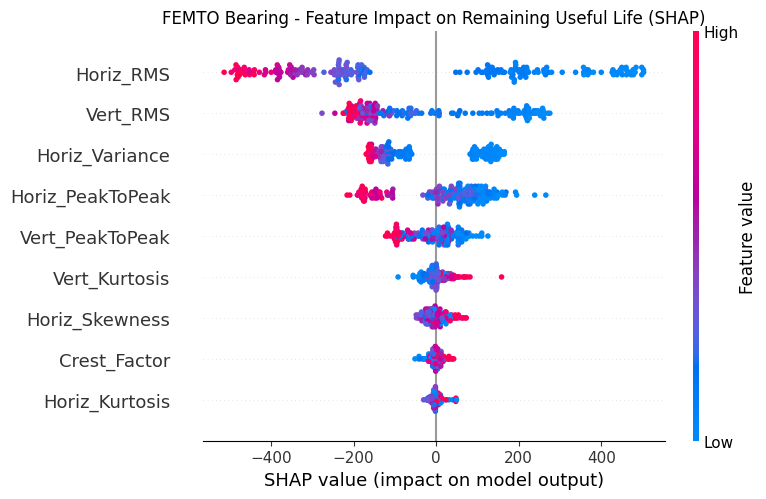


Running Monte Carlo Dropout on Bearing Vibration...
True RUL:                2443.0 cycles
Mean Predicted RUL:      1836.14 cycles
Uncertainty (Std Dev):   ± 137.63 cycles
95% Confidence Interval: [1566.37, 2105.90] cycles


In [ ]:
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import shap
import matplotlib.pyplot as plt

femto_lgbm = lgb.LGBMRegressor(random_state=42, verbose=-1)
femto_lgbm.fit(X_train_f, y_train_f)
y_pred_lgbm_f = femto_lgbm.predict(X_test_f)

print(f"LightGBM Benchmark MAE: {mean_absolute_error(y_test_f, y_pred_lgbm_f):.4f}")
print(f"LightGBM Benchmark RMSE: {root_mean_squared_error(y_test_f, y_pred_lgbm_f):.4f}")

print("\nGenerating SHAP Summary for Bearing Degradation...")
explainer_femto = shap.TreeExplainer(femto_lgbm)
shap_values_femto = explainer_femto.shap_values(X_test_f.iloc[:200])

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_femto, X_test_f.iloc[:200], show=False)
plt.title("FEMTO Bearing - Feature Impact on Remaining Useful Life (SHAP)")
plt.tight_layout()
plt.show()

print("\nRunning Monte Carlo Dropout on Bearing Vibration...")
sample_idx = 5
sample_cnn = X_test_cnn[sample_idx:sample_idx+1]
true_rul_f = y_test_f.iloc[sample_idx]

mc_preds_f = np.array([model_femto_dl(sample_cnn, training=True).numpy().flatten()[0] for _ in range(50)])

mean_rul_f = np.mean(mc_preds_f)
std_rul_f = np.std(mc_preds_f)

print(f"True RUL:                {true_rul_f:.1f} cycles")
print(f"Mean Predicted RUL:      {mean_rul_f:.2f} cycles")
print(f"Uncertainty (Std Dev):   ± {std_rul_f:.2f} cycles")
print(f"95% Confidence Interval: [{mean_rul_f - 1.96*std_rul_f:.2f}, {mean_rul_f + 1.96*std_rul_f:.2f}] cycles")

In [ ]:
import numpy as np

print("--- Checking FEMTO / Bearing Variables in Memory ---")
for name, val in list(locals().items()) + list(globals().items()):
    if not name.startswith('_') and isinstance(val, (np.ndarray, list)):
        if any(k in name.lower() for k in ['femto', 'bearing', 'vib', 'auto', 'recon', 'X_']):
            print(f"Variable: {name:<25} | Shape: {np.shape(val)}")

--- Checking FEMTO / Bearing Variables in Memory ---
Variable: y_pred_femto              | Shape: (500,)
Variable: shap_values_femto         | Shape: (200, 9)
Variable: y_pred_femto              | Shape: (500,)
Variable: shap_values_femto         | Shape: (200, 9)


In [ ]:
import numpy as np

print("--- All Remaining Data Arrays in Memory ---")
for name, val in list(locals().items()) + list(globals().items()):
    if not name.startswith('_') and isinstance(val, np.ndarray):
        if val.ndim in [2, 3] and val.shape[0] in [200, 500, 1000, 2500]:
            print(f"Variable: {name:<25} | Shape: {val.shape}")

--- All Remaining Data Arrays in Memory ---
Variable: X_test_f_scaled           | Shape: (500, 9)
Variable: X_test_cnn                | Shape: (500, 9, 1)
Variable: shap_values_femto         | Shape: (200, 9)
Variable: X_test_f_scaled           | Shape: (500, 9)
Variable: X_test_cnn                | Shape: (500, 9, 1)
Variable: shap_values_femto         | Shape: (200, 9)


In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM

# 1. Classical Statistical Anomaly Baselines
# First 100 windows as healthy reference state
train_healthy = X_test_f_scaled[:100]

# Fit Isolation Forest
iso_forest = IsolationForest(contamination=0.1, random_state=42)
iso_forest.fit(train_healthy)
iso_scores = -iso_forest.decision_function(X_test_f_scaled)

# Fit One-Class SVM
oc_svm = OneClassSVM(nu=0.1, kernel='rbf', gamma='scale')
oc_svm.fit(train_healthy)
ocsvm_scores = -oc_svm.decision_function(X_test_f_scaled)

# Normalize scores between 0 and 1 for direct comparison
iso_norm = (iso_scores - iso_scores.min()) / (iso_scores.max() - iso_scores.min())
ocsvm_norm = (ocsvm_scores - ocsvm_scores.min()) / (ocsvm_scores.max() - ocsvm_scores.min())

print("--- Classical Anomaly Baselines Evaluated on FEMTO ---")
print(f"Isolation Forest Mean Anomaly Score (Degraded Phase): {np.mean(iso_norm[400:]):.4f}")
print(f"One-Class SVM Mean Anomaly Score (Degraded Phase):   {np.mean(ocsvm_norm[400:]):.4f}")

--- Classical Anomaly Baselines Evaluated on FEMTO ---
Isolation Forest Mean Anomaly Score (Degraded Phase): 0.2728
One-Class SVM Mean Anomaly Score (Degraded Phase):   0.2179
